In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import os

# Load all PADLOC results
output_dir = "/home/ottena/mags_project/padloc_analysis/output"
all_files = glob.glob(os.path.join(output_dir, "*/*_padloc.csv"))

dfs = []
for f in all_files:
    genome = f.split("/")[-2]
    df = pd.read_csv(f)
    df["genome"] = genome
    dfs.append(df)

df = pd.concat(dfs, ignore_index=True)

# Load labels
labels = pd.read_csv("/home/ottena/mags_project/pankmer_analysis/label_lookup_v3.csv")
df = df.merge(labels, left_on="genome", right_on="original_name", how="left")

# Assign groups
def get_group(row):
    if "NCBI" in str(row["plot_label"]):
        return "NCBI Reference"
    elif "Masinjere" in str(row["plot_label"]):
        return "Masinjere MAG"
    elif "Limera" in str(row["plot_label"]):
        return "Limera MAG"
    else:
        return "Unknown"

df["group"] = df.apply(get_group, axis=1)

print(df.shape)
print(df["group"].value_counts())
print(df["system"].value_counts().head(10))

(2734, 23)
group
Masinjere MAG     987
NCBI Reference    922
Limera MAG        825
Name: count, dtype: int64
system
cas_type_III-A    322
DMS_other         275
RM_type_I         246
cas_type_I-C      230
RM_type_II        184
cas_type_I-F1     133
cas_type_other     64
brex_type_I        60
PD-T4-6            59
SoFic              56
Name: count, dtype: int64


In [2]:
# Genome order
genome_order = df.groupby(["plot_label", "group"]).size().reset_index(name="total")
genome_order = genome_order.sort_values(["group", "total"], ascending=[True, False])

# Group positions for dividers
groups = genome_order["group"].values
group_positions = {}
for g in ["NCBI Reference", "Limera MAG", "Masinjere MAG"]:
    idxs = [i for i, x in enumerate(groups) if x == g]
    if idxs:
        group_positions[g] = (min(idxs), max(idxs))

# Functional categories for PADLOC system names
functional_map = {
    "RM_type_I": "Restriction-Modification",
    "RM_type_II": "Restriction-Modification",
    "RM_type_III": "Restriction-Modification",
    "RM_type_IIG": "Restriction-Modification",
    "cas_type_I-C": "CRISPR-Cas",
    "cas_type_I-F1": "CRISPR-Cas",
    "cas_type_III-A": "CRISPR-Cas",
    "cas_type_other": "CRISPR-Cas",
    "brex_type_I": "DNA Methylation & BREX",
    "brex_type_IV": "DNA Methylation & BREX",
    "DMS_other": "DNA Modification & Other",
    "SoFic": "Toxin-Antitoxin",
    "septu_type_I": "Toxin-Antitoxin",
    "cbass_other": "Innate-like / Other",
    "zorya_type_I": "Innate-like / Other",
    "wadjet_type_III": "Innate-like / Other",
    "AbiE": "Abortive Infection",
    "VSPR": "Innate-like / Other",
    "PD-T4-6": "Innate-like / Other",
    "PDC-S05": "Innate-like / Other",
    "PDC-S04": "Innate-like / Other",
    "PDC-M33": "Innate-like / Other",
    "PDC-S13": "Innate-like / Other",
}

df["functional_category"] = df["system"].map(functional_map).fillna("Innate-like / Other")

print(df["functional_category"].value_counts())

functional_category
Innate-like / Other         1040
CRISPR-Cas                   749
Restriction-Modification     468
DNA Modification & Other     275
Toxin-Antitoxin               98
DNA Methylation & BREX        64
Abortive Infection            40
Name: count, dtype: int64


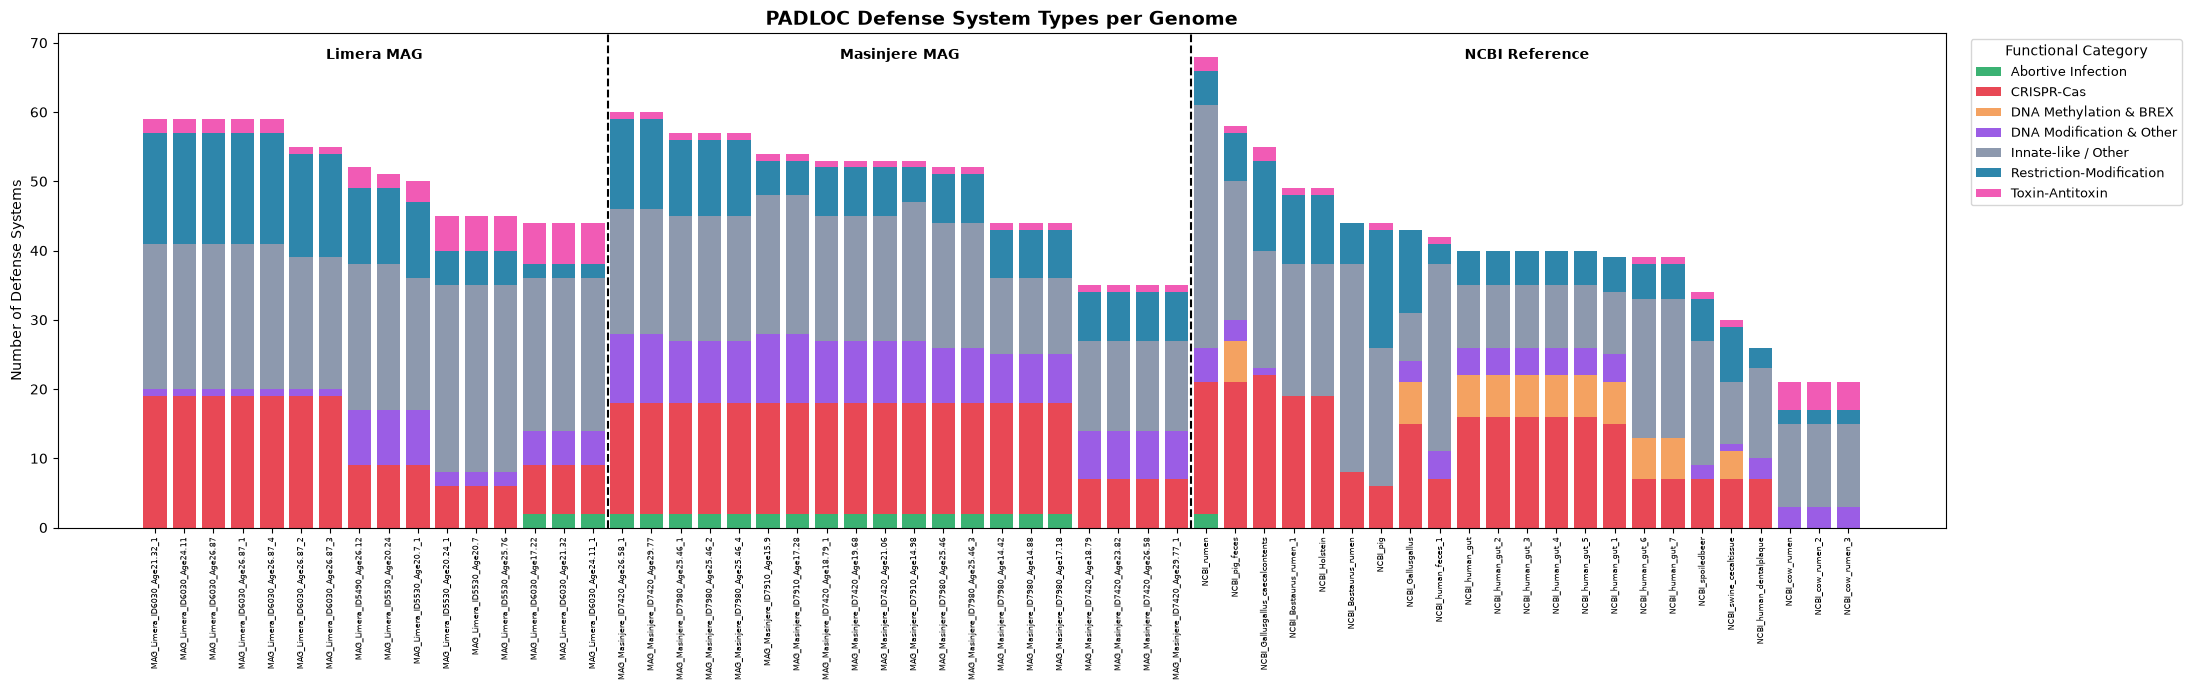

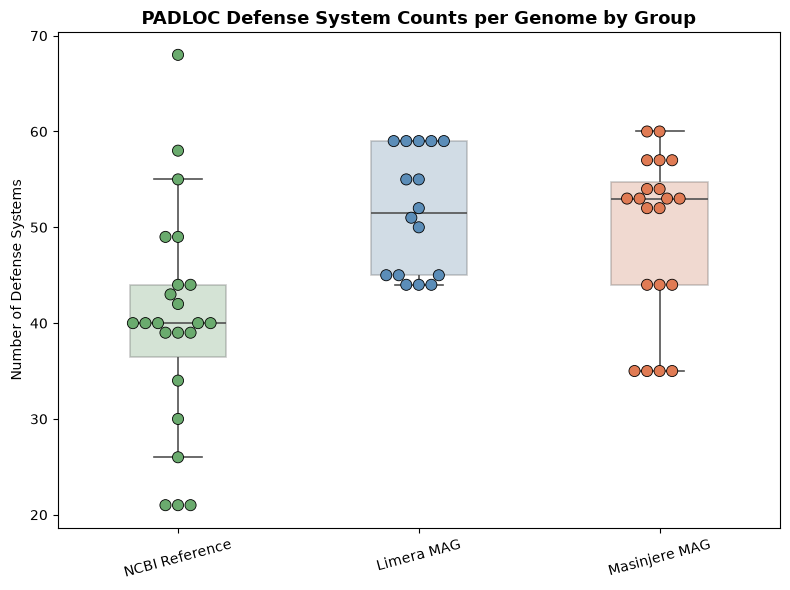

All figures saved!


In [6]:
# Better colors for functional categories
func_colors = {
    "Restriction-Modification": "#2E86AB",
    "CRISPR-Cas": "#E84855",
    "Abortive Infection": "#3BB273",
    "DNA Methylation & BREX": "#F4A261",
    "DNA Modification & Other": "#9B5DE5",
    "Toxin-Antitoxin": "#F15BB5",
    "Innate-like / Other": "#8D99AE",
}

# --- Figure 1: Per-genome stacked bar by functional category ---
pivot_func = df.groupby(["plot_label", "functional_category"]).size().unstack(fill_value=0)
pivot_func = pivot_func.loc[genome_order["plot_label"]]

fig, ax = plt.subplots(figsize=(22, 7))
bottom = pd.Series([0] * len(pivot_func), index=pivot_func.index)
for cat in pivot_func.columns:
    ax.bar(range(len(pivot_func)), pivot_func[cat], bottom=bottom,
           label=cat, color=func_colors.get(cat, "grey"), edgecolor="none", width=0.8)
    bottom += pivot_func[cat]

dividers = [i for i in range(1, len(groups)) if groups[i] != groups[i-1]]
for d in dividers:
    ax.axvline(x=d - 0.5, color="black", linewidth=1.5, linestyle="--")
for g, (start, end) in group_positions.items():
    ax.text((start + end) / 2, ax.get_ylim()[1] * 0.97, g, ha="center", va="top", fontsize=10, fontweight="bold")

ax.set_xticks(range(len(pivot_func)))
ax.set_xticklabels(pivot_func.index, rotation=90, fontsize=5.5)
ax.set_ylabel("Number of Defense Systems")
ax.set_title("PADLOC Defense System Types per Genome", fontsize=14, fontweight="bold")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=9, title="Functional Category")
plt.tight_layout()
plt.savefig("/home/ottena/mags_project/padloc_analysis/fig_stacked_bar.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Figure 2: Swarm + box ---
genome_counts = df.groupby(["plot_label", "group"]).size().reset_index(name="count")
group_order_list = ["NCBI Reference", "Limera MAG", "Masinjere MAG"]
group_colors = {"Masinjere MAG": "#E07B54", "Limera MAG": "#5B8DB8", "NCBI Reference": "#6AAB6E"}

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(data=genome_counts, x="group", y="count", hue="group",
            order=group_order_list, palette=group_colors, width=0.4, linewidth=1.2,
            fliersize=0, boxprops=dict(alpha=0.3), legend=False, ax=ax)
sns.swarmplot(data=genome_counts, x="group", y="count", hue="group",
              order=group_order_list, palette=group_colors, size=8,
              edgecolor="black", linewidth=0.6, legend=False, ax=ax)

ax.set_xlabel("")
ax.set_ylabel("Number of Defense Systems")
ax.set_title("PADLOC Defense System Counts per Genome by Group", fontsize=13, fontweight="bold")
ax.tick_params(axis="x", rotation=15)
plt.tight_layout()
plt.savefig("/home/ottena/mags_project/padloc_analysis/fig_swarm.png", dpi=300, bbox_inches="tight")
plt.show()
print("All figures saved!")

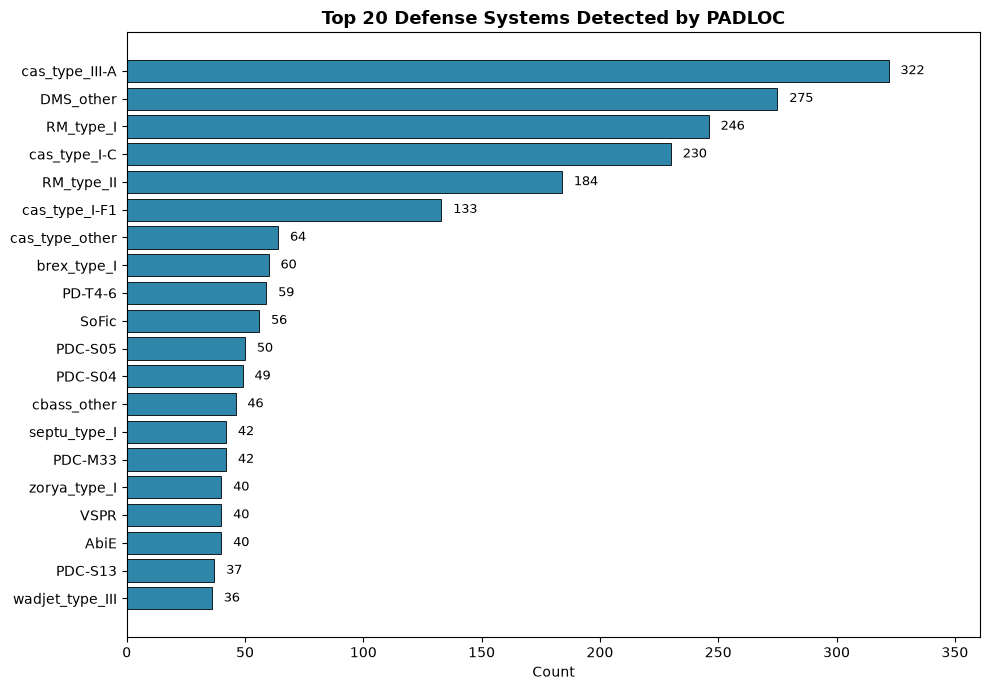

Saved!


In [7]:
# Top 20 defense systems overall
top20 = df["system"].value_counts().head(20)

fig, ax = plt.subplots(figsize=(10, 7))
bars = ax.barh(top20.index[::-1], top20.values[::-1], 
               color="#2E86AB", edgecolor="black", linewidth=0.6)

ax.set_xlabel("Count")
ax.set_title("Top 20 Defense Systems Detected by PADLOC", fontsize=13, fontweight="bold")

# Add count labels
for bar, val in zip(bars, top20.values[::-1]):
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            str(val), va="center", fontsize=9)

ax.set_xlim(0, top20.values.max() * 1.12)
plt.tight_layout()
plt.savefig("/home/ottena/mags_project/padloc_analysis/fig_top20.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved!")

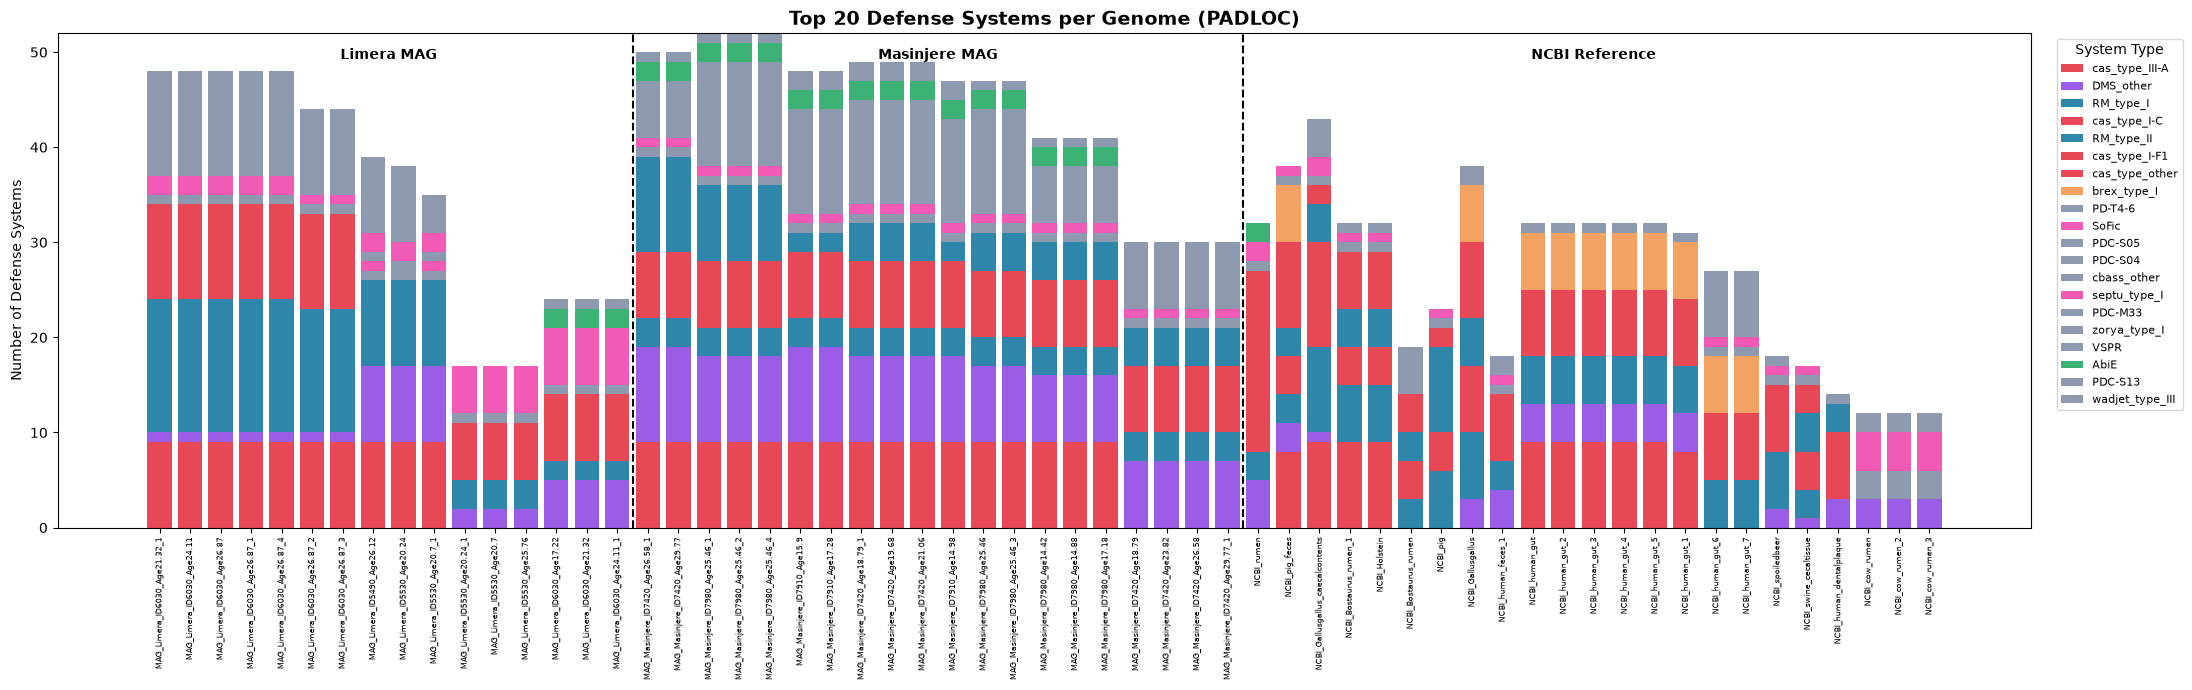

Saved!


In [8]:
# Top 20 systems overall (to know which to show)
top20_systems = df["system"].value_counts().head(20).index.tolist()

# Filter to top 20 and pivot by genome
df_top20 = df[df["system"].isin(top20_systems)]
pivot_top20 = df_top20.groupby(["plot_label", "system"]).size().unstack(fill_value=0)
pivot_top20 = pivot_top20.loc[genome_order["plot_label"]]
pivot_top20 = pivot_top20[top20_systems]  # keep top20 order

# Color each system by functional category
sys_to_func = df[["system", "functional_category"]].drop_duplicates().set_index("system")["functional_category"]
bar_colors = [func_colors.get(sys_to_func.get(s, "Innate-like / Other"), "#8D99AE") for s in top20_systems]

fig, ax = plt.subplots(figsize=(22, 7))
bottom = pd.Series([0] * len(pivot_top20), index=pivot_top20.index)
for sys_type, color in zip(top20_systems, bar_colors):
    ax.bar(range(len(pivot_top20)), pivot_top20[sys_type], bottom=bottom,
           label=sys_type, color=color, edgecolor="none", width=0.8)
    bottom += pivot_top20[sys_type]

dividers = [i for i in range(1, len(groups)) if groups[i] != groups[i-1]]
for d in dividers:
    ax.axvline(x=d - 0.5, color="black", linewidth=1.5, linestyle="--")
for g, (start, end) in group_positions.items():
    ax.text((start + end) / 2, ax.get_ylim()[1] * 0.97, g,
            ha="center", va="top", fontsize=10, fontweight="bold")

ax.set_xticks(range(len(pivot_top20)))
ax.set_xticklabels(pivot_top20.index, rotation=90, fontsize=5.5)
ax.set_ylabel("Number of Defense Systems")
ax.set_title("Top 20 Defense Systems per Genome (PADLOC)", fontsize=14, fontweight="bold")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8, title="System Type")
plt.tight_layout()
plt.savefig("/home/ottena/mags_project/padloc_analysis/fig_top20_per_genome.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved!")